# Cheaper quantum circuits, checked by a machine that tests every answer

**Google Quantum AI - Verifiable Quantum Circuit Compilation | work in progress**

**Status (7 Nov 2026):** invsqrt and dqi are improved and pass the official verifiers. dfthcsos is not started yet (the untouched sample is used).
**Leaderboard score:** *(fill in after the first submission is scored)*

---

## TL;DR

| Task | Sample (reference) | Ours | Improvement | Checked with |
|---|---|---|---|---|
| invsqrt (fusion energy) | score 2,076,774 (260 qubits, 7,735 Toffolis) | **555,080** (164 qubits, 3,139 Toffolis) | **3.74x** | official verifier, all 200,540,928 shots passed |
| dqi (optimization) | score about 2.44e13 (1,893 qubits, 5,725,461 Toffolis) | **2.11e13** (1,893 qubits, 4,951,506 Toffolis) | **1.16x** | official verifier, 102,400 shots, 0 errors |
| dfthcsos (chemistry) | sample | sample (not started) | 1.00x | - |
| **Combined (geometric mean)** | | | **about 1.63x** | estimate until the leaderboard scores it |

The dqi reference score is computed from the competition formula and the paper's numbers, not by running the sample file. For context, the top public score when this was written is about 29, so this is a start, not a finish.

---

## The problem in plain English

A future quantum computer has to fix its own errors, and that makes every gate and every qubit expensive. The most expensive gate is the **Toffoli**, so the cost of a circuit is mostly **how many qubits it uses** and **how many Toffolis it runs**. The competition asks us to rebuild three important sub-circuits so they use fewer of both.

The trick that makes this a fair contest: these circuits only use reversible classical logic and phase gates, so a normal computer can check them. The **verifier** runs the circuit on many inputs and checks three things on each run:

1. the input is restored,
2. every scratch qubit is back to 0,
3. the phase is correct (within the allowed error).

Each task has its own cost formula, and the final score is the **geometric mean** of the three improvements over the sample. One weak task therefore drags the whole score down.

| Task | What the circuit does | Cost (lower is better) |
|---|---|---|
| invsqrt | applies a phase of 1/sqrt(x) turns, for the Coulomb force between electrons | qubits x (Toffolis + T gates / 4) |
| dqi | decodes a Reed-Solomon code inside a quantum algorithm | repetition factor x qubits^2 x Toffolis |
| dfthcsos | loads chemistry data for the FeMoCo molecule | lambda x Toffolis x qubits |

---

## invsqrt: from 2.08 million to 0.555 million

**What the sample does.** It shifts x into a fixed range, guesses 1/sqrt(x) with a cubic polynomial, then polishes the guess with one Newton-Raphson step (the same idea as the famous Quake III trick, but in fixed-point arithmetic and reversible).

**Where the cost was.** I counted Toffolis stage by stage. The Newton step (four multiplications) was 62% of the circuit, and the cubic polynomial was another 27%.

**Step 1: tune the register widths (5% better).** The sample's error is 2^-25.07 against a limit of 2^-24, so there is some slack. A classical model of the circuit (checked against the simulator) let me test every width setting in seconds. Four settings could each be lowered by one bit, and the best combination gave 256 qubits and 7,447 Toffolis. Lowering anything by two bits, or the coefficient width by even one, broke the error limit.

**Step 2: replace the Newton step with a lookup table (3.7x better).** A table lookup costs about one Toffoli per entry, far less than a multiplication. If the table is big enough, the first guess is already accurate to 2^-24 and the Newton step is not needed at all. I searched over table sizes and polynomial degrees with the classical model. The best was **384 table rows (the top 9 bits of the shifted input), with a quadratic polynomial per row**.

| Stage | Width-tuned reference | Ours |
|---|---|---|
| Newton step | 4,606 | 0 |
| Polynomial | 2,028 | 1,778 |
| Table lookup | 0 | 551 |
| Normalize + denormalize | 810 | 810 |
| **Total Toffolis** | **7,447** | **3,139** |
| Qubits | 256 | 164 |

Dropping the Newton step also frees the registers it needed, which is why qubits fall from 256 to 164.

**Result.** The official verifier passes all 200,540,928 shots (every input from 1 to 3,133,452, 64 times each). The worst error uses 47% of the allowed tolerance.

---

## dqi: from 5.73 million to 4.95 million Toffolis

**What the sample does.** It decodes a Reed-Solomon code with the Extended Euclidean Algorithm (222 steps), then runs a Chien search over all 4,095 positions, and finally runs the first part backwards to clean up. I rebuilt the reference circuit exactly (1,893 qubits and 5,725,461 Toffolis, the paper's numbers) and measured each part by switching it off.

| Part | Toffolis | Share |
|---|---|---|
| Field multiplications in the EEA | 2,430,600 | 42.5% |
| Register swaps | 1,107,264 | 19.3% |
| Inversions in the Chien search (4,095 x 315) | 1,289,925 | 22.5% |
| Rest of the Chien search | 154,812 | 2.7% |
| Divisions in the EEA | 167,832 | 2.9% |
| Counters, comparisons, addressing | 575,028 | 10.0% |

**The change.** Each position needs the inverse of a 12-bit field element, which the sample computes with five full multiplications (315 Toffolis). Splitting the field into a tower, GF(2^12) built on GF(2^6), turns one inversion into **one 6-bit multiplication, one 6-bit inversion and two more 6-bit multiplications: 126 Toffolis**. This is a standard idea from classical field arithmetic; the work was making it exact and reversible here. Switching between the two number representations costs no Toffolis.

**Result.** 4,951,506 Toffolis (the predicted number exactly), the same 1,893 qubits, and **1.16x** on the dqi score. The official verifier passes all 102,400 shots with 0 value errors and 0 phase errors. The repetition factor is 1.1913, the same floor an exact decoder gets.

---

## How we made sure it is correct

1. **A classical model of each circuit** that predicts the exact output bits, checked against the kickmix simulator.
2. **Tests that must fail.** The test harness reports failures on a deliberately broken decoder (130 of 256 shots), so a pass means something.
3. **Exhaustive small tests.** The new inversion was checked on all 4,096 inputs, including zero: right answer, input unchanged, scratch qubits clean, no stray phase.
4. **The official verifiers** on the final files, and a byte-for-byte check that the zip holds exactly the files we tested.

A bug we caught on the way: the first dqi build forgot to free the inversion's scratch qubits, so every one of the 4,095 positions leaked 12 qubits (51,033 qubits in total). The qubit count in the build output exposed it immediately.

---

## What did not work, and the limits

- Lowering any invsqrt register width by two bits, or the coefficient width by one, breaks the 2^-24 error limit.
- A degree-1 table with 48 rows reaches only 2^-24.4 after a Newton step, too close to the limit once rounding is included.
- The dqi decoder is allowed to fail on some inputs, but failure is expensive: at a 1% failure rate the repetition factor is 1.94. So we kept the decoder exact.
- dqi qubits are unchanged: 840 hold the input and about 876 hold the second polynomial array, so this change only cut Toffolis.

---

## Plan

1. **Submit this version** and check it scores the same on the leaderboard (it uses a secret salt for the random test shots).
2. **invsqrt:** a binary barrel shifter for the denormalize step (an estimated 300 fewer Toffolis), spend the spare error margin (47% of tolerance is used), and tune the coefficient rounding.
3. **dqi:** use the tower inversion for the EEA divisions (about 1.7%), a cheaper multiplier without extra qubits (63 to 54 Toffolis, about 6%), and the multiplication sweep, which runs 73 controlled multiplications in each of the 222 iterations even when the control is off. That last one is the biggest prize and needs a restructure.
4. **dfthcsos:** not started. It needs the starter kit and a classical optimization of the Hamiltonian factorization.

---

## Reproduce

- `make_invsqrt.py` builds the invsqrt circuit (lookup table plus quadratic).
- `make_dqi_v1.py` patches the competition's reference decoder with the tower inversion and builds the dqi circuit.
- Official checks: `verify_submission_invsqrt.py` and `verify_submission_dqi.py` from the competition's `verifiers/` folder.

## Credits

- Competition and paper: Khattar, Rubin, Gidney, Broughton, Low, Babbush et al., *Leveraging verifiable structure in quantum circuits to find more efficient compilations with agentic AI* (arXiv:2610.23832), and the open-source **kickmix** simulator in Qualtran.
- Built step by step with an AI coding assistant (Claude) in a closed loop with the official verifiers, the workflow the competition is designed to encourage.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/verifiable_circuit_compilation.pdf
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/kickmix/LICENSE.txt
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/kickmix/kickmix.so
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/sample_submission/dqi.kmb
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/sample_submission/invsqrt.kmb
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/sample_submission/dfthcsos/angle_k_9.kmb
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/sample_submission/dfthcsos/submission.npz
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/sample_submission/dfthcsos/angle_k_8.kmb
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/sample_submission/dfthcsos/angle_k_7.kmb
/kaggle/input/competitions/google-verifiable-qua

In [2]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count("/") - 2
    if depth <= 3:
        print(root, "-", len(files), "files")

/kaggle/input - 0 files
/kaggle/input/competitions - 0 files
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation - 1 files
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/kickmix - 2 files
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/sample_submission - 2 files
/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/verifiers - 1 files


In [3]:
import os
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
for root, dirs, files in os.walk(base):
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f"{os.path.getsize(p):>12,}  {p.replace(base, '')}")

   1,092,999  /verifiable_circuit_compilation.pdf
      11,358  /kickmix/LICENSE.txt
   3,220,392  /kickmix/kickmix.so
 886,118,180  /sample_submission/dqi.kmb
     579,721  /sample_submission/invsqrt.kmb
   1,671,932  /sample_submission/dfthcsos/angle_k_0.kmb
   1,662,896  /sample_submission/dfthcsos/angle_k_1.kmb
   1,665,821  /sample_submission/dfthcsos/angle_k_2.kmb
   1,666,802  /sample_submission/dfthcsos/angle_k_3.kmb
   1,954,082  /sample_submission/dfthcsos/angle_k_4.kmb
   1,948,583  /sample_submission/dfthcsos/angle_k_5.kmb
   1,947,980  /sample_submission/dfthcsos/angle_k_6.kmb
   1,968,527  /sample_submission/dfthcsos/angle_k_7.kmb
   1,957,124  /sample_submission/dfthcsos/angle_k_8.kmb
   1,953,830  /sample_submission/dfthcsos/angle_k_9.kmb
   4,537,436  /sample_submission/dfthcsos/submission.npz
      11,358  /verifiers/LICENSE.txt
          84  /verifiers/invsqrt/__init__.py
      18,862  /verifiers/invsqrt/nr_reference_circuit.py
      17,210  /verifiers/invsqrt/verify

In [4]:
import sys, re
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
sys.path.insert(0, base + "/kickmix")
import kickmix as km
print("kickmix loaded from:", km.__file__)

# 1) Load the sample invsqrt circuit and count things
c = km.Circuit.from_file(base + "/sample_submission/invsqrt.kmb")
print("qubits:", c.num_qubits)
try:
    print(c.operation_statistics)
except Exception as e:
    print("stats error:", e)

# 2) Show the function names and command-line options in the verifier
src = open(base + "/verifiers/invsqrt/verify_submission_invsqrt.py").read()
for line in src.splitlines():
    if re.match(r"\s*(def |class |import |from |parser\.add_argument)", line):
        print(line)

kickmix loaded from: /kaggle/input/competitions/google-verifiable-quantum-circuit-compilation/kickmix/kickmix.so
qubits: 260
<bound method PyCapsule.operation_statistics of km.Circuit('''
    APPEND_TO_REGISTER q0 r0
    APPEND_TO_REGISTER q1 r0
    APPEND_TO_REGISTER q2 r0
    APPEND_TO_REGISTER q3 r0
    APPEND_TO_REGISTER q4 r0
    APPEND_TO_REGISTER q5 r0
    APPEND_TO_REGISTER q6 r0
    APPEND_TO_REGISTER q7 r0
    APPEND_TO_REGISTER q8 r0
    APPEND_TO_REGISTER q9 r0
    APPEND_TO_REGISTER q10 r0
    APPEND_TO_REGISTER q11 r0
    APPEND_TO_REGISTER q12 r0
    APPEND_TO_REGISTER q13 r0
    APPEND_TO_REGISTER q14 r0
    APPEND_TO_REGISTER q15 r0
    APPEND_TO_REGISTER q16 r0
    APPEND_TO_REGISTER q17 r0
    APPEND_TO_REGISTER q18 r0
    APPEND_TO_REGISTER q19 r0
    APPEND_TO_REGISTER q20 r0
    APPEND_TO_REGISTER q21 r0
    REGISTER r0 "x"
    INFO_TAG "@enter:compute_y1"
    INFO_TAG "@enter:normalize"
    X q20
    X q21
    R q62
    CCX q20 q21 q62
    X q20
    X q21
    INF

In [5]:
import sys, re
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
sys.path.insert(0, base + "/kickmix")
import kickmix as km

c = km.Circuit.from_file(base + "/sample_submission/invsqrt.kmb")
print("qubits:", c.num_qubits)

# call it with () this time, and cut the text short just in case
stats = c.operation_statistics()
print(str(stats)[:1500])

# verifier: print only the names of functions and command-line options
src = open(base + "/verifiers/invsqrt/verify_submission_invsqrt.py").read()
for line in src.splitlines():
    if re.match(r"\s*(def |class |parser\.add_argument)", line):
        print(line[:120])

qubits: 260
<km.OperationStatistics num_instructions=62160 num_toffoli_like=7735 num_t_like=1>
class ProblemSpecInvSqrt:
    def for_n_p(
    def num_shots(self) -> int:
def reference_values(spec: ProblemSpecInvSqrt, xs: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
def half_turns_to_units(half_turns: int | Fraction) -> int:
def z_pow_class(half_turns: Fraction) -> str:
def rotation_t_count(eps: float) -> float:
def _circuit_sha256(circuit: km.Circuit) -> str:
def _initial_seed(circuit_hash: str, salt: str) -> int:
def to_bits(values: np.ndarray, width: int) -> np.ndarray:
def from_bits(bits: np.ndarray) -> np.ndarray:
def validate_registers(circuit: km.Circuit, spec: ProblemSpecInvSqrt
def sample_shots(spec: ProblemSpecInvSqrt, start: int, stop: int) -> np.ndarray:
def _call_worker(task):
def _run_parallel(fn, tasks: list, max_workers: int | None) -> list:
def verify(circuit: km.Circuit, spec: ProblemSpecInvSqrt, *, seed: int | None = None,
    def run_chunk(task: tuple[int, int, int]

In [6]:
import os, time
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
os.environ["PYTHONPATH"] = base + "/kickmix"
t = time.time()
!python {base}/verifiers/invsqrt/verify_submission_invsqrt.py {base}/sample_submission/invsqrt.kmb --max-x 5000 --shots-per-x 2
print("seconds:", round(time.time() - t, 1))

{
  "status": "FAIL",
  "error": "num_shots must be a multiple of batch_size=256, got 10000."
}
seconds: 0.4


In [7]:
import os, time
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
os.environ["PYTHONPATH"] = base + "/kickmix"
t = time.time()
!python {base}/verifiers/invsqrt/verify_submission_invsqrt.py {base}/sample_submission/invsqrt.kmb --max-x 4096 --shots-per-x 4
print("seconds:", round(time.time() - t, 1))

{
  "status": "PASS",
  "score": 2069865.059331096,
  "toffoli_equivalent": 7961.019458965754,
  "toffoli_count": 7735.0,
  "max_toffoli_count": 7735,
  "t_count": 1.0,
  "rotation_count": 37.0,
  "rotation_eps": 5.35414837554282e-11,
  "num_qubits": 260,
  "reaction_depth": 4005,
  "num_ops": 62160,
  "verified_shots": 16384,
  "worst_error_over_tolerance": 0.42871093750805755,
  "worst_x": 729,
  "circuit_sha256": "e2bf8eb64350a4460a271fc7f1d591ef125b1e276377e9a0f64b96ab3ca321e1"
}
seconds: 0.6


In [8]:
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
print(open(base + "/verifiers/invsqrt/nr_reference_circuit.py").read())

"""Reference Newton-Raphson circuit for Benchmark I (see `verify_submission_invsqrt.py`).

Implements the three-step algorithm of the paper with kickmix arithmetic, for `beta = 1`:

1. Normalize. Count the leading zero *pairs* `s` of `x` into a unary register and shift
   `x` in place to `x_norm = x 2^(2s)`, so that `M = x_norm / 2^(2 n_p)` lies in `[1, 4)`
   and `1 / sqrt(x) = 2^(s - n_p) / sqrt(M)`.
2. Initial guess. `y0 ~ 1 / sqrt(M)` from one of four cubic polynomials, chosen by the top
   three bits of `x_norm` (coefficients loaded by a Clifford network from two AND bits),
   evaluated by Horner's rule on `delta = M - {1, 1.5, 2, 3}` with column-truncated
   multipliers: `r1 = c2 - T(c3 delta)`, `r2 = c1 - T(r1 delta)`, `y0 = c0 - T(r2 delta)`.
3. Newton-Raphson. `p = T(y0 (3 - T(M T(y0^2)))) = 2 / sqrt(M)`, then de-normalize with
   a unary-controlled shift: `y1 = p 2^s`, so `y1 / 2^F = 1 / sqrt(x)` with
   `F = wp + n_p + 1` fractional bits of a turn.

`y1` is then used to phas

In [9]:
import sys, math, time, dataclasses
import numpy as np
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
sys.path.insert(0, base + "/kickmix")
sys.path.insert(0, base + "/verifiers/invsqrt")
import kickmix as km
import nr_reference_circuit as nr

N_P = 10
XS = np.arange(1, 3 * (2**N_P - 2)**2 + 1)
EXACT = 1 / np.sqrt(XS.astype(np.float64))

def evaluate(prec):
    try:
        rel = nr.relative_error(N_P, prec, XS)
        worst = float(rel.max())
        if worst >= 2**-24:
            return dict(ok=False, why=f"error 2^{math.log2(worst):.2f}")
        circ = nr.build_nr_circuit(N_P, prec=prec)
    except Exception as e:
        return dict(ok=False, why=type(e).__name__)
    st = circ.operation_statistics()
    q, tof = circ.num_qubits, st.num_toffoli_like
    margin = float(((2**-24 - rel) * EXACT).min())
    nrot = prec.output_bits(N_P) - 3
    eps = math.pi * margin / nrot
    rot_t = nrot * (0.56 * math.log2(1 / eps) + 5.3)
    c = tof + (st.num_t_like + rot_t) / 4
    return dict(ok=True, q=q, tof=tof, c=c, score=q * c, err=math.log2(worst))

base_prec = nr.Precision()
rows = []
def run(label, prec):
    t = time.time()
    r = evaluate(prec); r["label"] = label
    rows.append(r)
    if r["ok"]:
        print(f"{label:<22} Q={r['q']} Tof={r['tof']} score={r['score']:,.0f} err=2^{r['err']:.2f} ({time.time()-t:.0f}s)")
    else:
        print(f"{label:<22} REJECT: {r['why']} ({time.time()-t:.0f}s)")

run("baseline", base_prec)
for f in ["delta_bits", "coef_bits", "square_bits", "product_bits", "result_bits"]:
    for d in (1, 2, 4):
        run(f"{f} -{d}", dataclasses.replace(base_prec, **{f: getattr(base_prec, f) - d}))

baseline               Q=260 Tof=7735 score=2,076,774 err=2^-25.07 (6s)
delta_bits -1          Q=260 Tof=7621 score=2,047,432 err=2^-24.73 (6s)
delta_bits -2          REJECT: error 2^-23.98 (6s)
delta_bits -4          REJECT: error 2^-21.11 (6s)
coef_bits -1           REJECT: error 2^-23.58 (6s)
coef_bits -2           REJECT: error 2^-21.57 (5s)
coef_bits -4           REJECT: OverflowError (1s)
square_bits -1         Q=259 Tof=7663 score=2,052,009 err=2^-24.18 (6s)
square_bits -2         REJECT: error 2^-23.37 (6s)
square_bits -4         REJECT: OverflowError (6s)
product_bits -1        Q=258 Tof=7645 score=2,041,062 err=2^-24.12 (6s)
product_bits -2        REJECT: error 2^-23.17 (6s)
product_bits -4        REJECT: error 2^-21.16 (6s)
result_bits -1         Q=259 Tof=7647 score=2,044,964 err=2^-24.61 (6s)
result_bits -2         REJECT: error 2^-23.76 (6s)
result_bits -4         REJECT: error 2^-21.69 (6s)


In [10]:
import itertools
best = None
for cb in (0, 1):
    for combo in itertools.product((0, -1), repeat=4):
        if combo == (0, 0, 0, 0) and cb == 0:
            continue
        p = dataclasses.replace(
            base_prec,
            coef_bits=base_prec.coef_bits + cb,
            delta_bits=base_prec.delta_bits + combo[0],
            square_bits=base_prec.square_bits + combo[1],
            product_bits=base_prec.product_bits + combo[2],
            result_bits=base_prec.result_bits + combo[3],
        )
        r = evaluate(p)
        if r["ok"]:
            tag = f"coef{cb:+d} d{combo[0]} sq{combo[1]} pr{combo[2]} re{combo[3]}"
            print(f"{tag:<28} Q={r['q']} Tof={r['tof']} score={r['score']:,.0f} err=2^{r['err']:.2f}")
            if best is None or r["score"] < best[0]:
                best = (r["score"], p, tag)

print("BEST:", best[2], f"{best[0]:,.0f}")
circ = nr.build_nr_circuit(N_P, prec=best[1])
circ.to_file("/kaggle/working/best_invsqrt.kmb", format="kmb")
print(best[1])

coef+0 d0 sq0 pr0 re-1       Q=259 Tof=7647 score=2,044,964 err=2^-24.61
coef+0 d0 sq0 pr-1 re0       Q=258 Tof=7645 score=2,041,062 err=2^-24.12
coef+0 d0 sq0 pr-1 re-1      Q=256 Tof=7561 score=2,000,953 err=2^-24.20
coef+0 d0 sq-1 pr0 re0       Q=259 Tof=7663 score=2,052,009 err=2^-24.18
coef+0 d0 sq-1 pr0 re-1      Q=258 Tof=7575 score=2,018,729 err=2^-24.34
coef+0 d-1 sq0 pr0 re0       Q=260 Tof=7621 score=2,047,432 err=2^-24.73
coef+0 d-1 sq0 pr0 re-1      Q=259 Tof=7533 score=2,015,913 err=2^-24.45
coef+0 d-1 sq0 pr-1 re0      Q=258 Tof=7531 score=2,011,192 err=2^-24.16
coef+0 d-1 sq0 pr-1 re-1     Q=256 Tof=7447 score=1,971,483 err=2^-24.24
coef+0 d-1 sq-1 pr0 re0      Q=259 Tof=7549 score=2,022,483 err=2^-24.18
coef+0 d-1 sq-1 pr0 re-1     Q=258 Tof=7461 score=1,989,317 err=2^-24.34
coef+1 d0 sq0 pr0 re0        Q=264 Tof=8031 score=2,186,811 err=2^-24.82
coef+1 d0 sq0 pr0 re-1       Q=263 Tof=7939 score=2,153,289 err=2^-24.63
coef+1 d0 sq0 pr-1 re0       Q=262 Tof=7941 score=2

In [11]:
import os, time
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
os.environ["PYTHONPATH"] = base + "/kickmix"
t = time.time()
!python {base}/verifiers/invsqrt/verify_submission_invsqrt.py /kaggle/working/best_invsqrt.kmb --max-x 4096 --shots-per-x 4
print("seconds:", round(time.time() - t, 1))

{
  "status": "PASS",
  "score": 1962822.18647651,
  "toffoli_equivalent": 7667.274165923867,
  "toffoli_count": 7447.0,
  "max_toffoli_count": 7447,
  "t_count": 1.0,
  "rotation_count": 36.0,
  "rotation_eps": 5.0979113331076526e-11,
  "num_qubits": 256,
  "reaction_depth": 3844,
  "num_ops": 59717,
  "verified_shots": 16384,
  "worst_error_over_tolerance": 0.47046589953059126,
  "worst_x": 2047,
  "circuit_sha256": "9816fbfb5544949fb2c448410daf8144b825e45d0105cb118aac75c1a8c910e9"
}
seconds: 0.5


In [12]:
import os, time
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
os.environ["PYTHONPATH"] = base + "/kickmix"
t = time.time()
!python {base}/verifiers/invsqrt/verify_submission_invsqrt.py /kaggle/working/best_invsqrt.kmb
print("minutes:", round((time.time() - t) / 60, 1))

{
  "status": "PASS",
  "score": 1971483.438323478,
  "toffoli_equivalent": 7701.107180951086,
  "toffoli_count": 7447.0,
  "max_toffoli_count": 7447,
  "t_count": 1.0,
  "rotation_count": 36.0,
  "rotation_eps": 4.859684532075422e-13,
  "num_qubits": 256,
  "reaction_depth": 3844,
  "num_ops": 59717,
  "verified_shots": 200540928,
  "worst_error_over_tolerance": 0.8469246188549967,
  "worst_x": 2684414,
  "circuit_sha256": "9816fbfb5544949fb2c448410daf8144b825e45d0105cb118aac75c1a8c910e9"
}
minutes: 14.3


In [13]:
import re, collections
c = km.Circuit.from_file("/kaggle/working/best_invsqrt.kmb")
stack, count, total = [], collections.Counter(), 0
for line in str(c).splitlines():
    s = line.strip()
    m = re.match(r'INFO_TAG "@(enter|exit):(\w+)"', s)
    if m:
        if m.group(1) == "enter": stack.append(m.group(2))
        elif stack: stack.pop()
        continue
    op = s.split(" ")[0]
    if op in ("CCX", "CCZ", "CSWAP"):
        total += 1
        count[stack[-1] if stack else "(none)"] += 1
print("total toffoli-like:", total)
for k, v in count.most_common():
    print(f"{k:<20}{v:>6}  {100*v/total:5.1f}%")

total toffoli-like: 7447
isub                  2028   27.2%
iadd                  2028   27.2%
horner_step            780   10.5%
multiply_m             770   10.3%
multiply_y0            714    9.6%
left_rotate            400    5.4%
right_rotate           400    5.4%
square                 260    3.5%
iadd_classical          54    0.7%
normalize               10    0.1%
select_interval          3    0.0%


In [14]:
import re, collections
STAGES = ["normalize","select_interval","load_coefficients","horner","square",
          "multiply_m","correct","multiply_y0","denormalize","phase_by_bits"]
stack, cnt = [], collections.Counter()
for line in str(c).splitlines():
    s = line.strip()
    m = re.match(r'INFO_TAG "@(enter|exit):(\w+)"', s)
    if m:
        if m.group(1) == "enter": stack.append(m.group(2))
        elif stack: stack.pop()
        continue
    if s.split(" ")[0] in ("CCX", "CCZ", "CSWAP"):
        stage = next((t for t in stack if t in STAGES), "(none)")
        direction = "reverse" if "uncompute_y1" in stack else "forward"
        cnt[(stage, direction)] += 1
print(f"{'stage':<18}{'forward':>9}{'reverse':>9}{'total':>8}")
for st in STAGES + ["(none)"]:
    f, r = cnt[(st, "forward")], cnt[(st, "reverse")]
    if f + r:
        print(f"{st:<18}{f:>9}{r:>9}{f + r:>8}")

stage               forward  reverse   total
normalize               120      110     230
select_interval           3        0       3
horner                 1014     1014    2028
square                  442      442     884
multiply_m             1001     1001    2002
correct                  27       27      54
multiply_y0             833      833    1666
denormalize             290      290     580


In [15]:
import numpy as np, math

width = 22
xn = np.arange(2**(width-2), 2**width, dtype=np.int64)   # every normalized x with M in [1,4)
M = xn / 2.0**(width-2)
f = M**-0.5

def model(t, d):
    # t = number of top bits used as table index, d = polynomial degree per row
    y0 = np.empty_like(M)
    idx = xn >> (width - t)
    for i in np.unique(idx):
        sel = idx == i
        lo = i * 2.0**(width - t) / 2.0**(width-2)
        hi = lo + 2.0**(width - t) / 2.0**(width-2)
        nodes = (lo + hi)/2 + (hi - lo)/2 * np.cos(np.pi*(np.arange(64)+0.5)/64)
        coef = np.polyfit(nodes - lo, nodes**-0.5, d)
        y0[sel] = np.polyval(coef, M[sel] - lo)
    e0 = np.abs(y0 - f) / f
    y1 = 0.5 * y0 * (3 - M * y0**2)
    e1 = np.abs(y1 - f) / f
    return e0.max(), e1.max(), len(np.unique(idx))

print(f"{'t':>2} {'deg':>3} {'rows':>5} {'guess err':>10} {'after NR':>10}")
for d in (1, 2, 3):
    for t in range(3, 9):
        e0, e1, rows = model(t, d)
        flag = "  <-- ok" if e1 < 2**-25.5 else ""
        print(f"{t:>2} {d:>3} {rows:>5} 2^{math.log2(e0):>7.2f} 2^{math.log2(e1):>7.2f}{flag}")

 t deg  rows  guess err   after NR
 3   1     6 2^  -7.00 2^ -13.42
 4   1    12 2^  -8.73 2^ -16.88
 5   1    24 2^ -10.58 2^ -20.58
 6   1    48 2^ -12.50 2^ -24.41
 7   1    96 2^ -14.46 2^ -28.33  <-- ok
 8   1   192 2^ -16.44 2^ -32.29  <-- ok
 3   2     6 2^ -10.58 2^ -20.57
 4   2    12 2^ -13.16 2^ -25.74  <-- ok
 5   2    24 2^ -15.93 2^ -31.28  <-- ok
 6   2    48 2^ -18.81 2^ -37.03  <-- ok
 7   2    96 2^ -21.74 2^ -42.90  <-- ok
 8   2   192 2^ -24.71 2^ -48.74  <-- ok
 3   3     6 2^ -14.08 2^ -27.57  <-- ok
 4   3    12 2^ -17.52 2^ -34.46  <-- ok
 5   3    24 2^ -21.21 2^ -41.84  <-- ok
 6   3    48 2^ -25.05 2^ -49.28  <-- ok
 7   3    96 2^ -28.96 2^ -51.45  <-- ok
 8   3   192 2^ -32.92 2^ -51.46  <-- ok


In [16]:
import sys
BASE = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
sys.path.insert(0, BASE + "/kickmix")
 
import math, dataclasses
from fractions import Fraction
import numpy as np
import kickmix as km
 
N_P = 10
WIDTH = 2 * N_P + 2            # 22
MAX_X = 3 * (2**N_P - 2) ** 2  # 3,133,452
 
@dataclasses.dataclass(frozen=True)
class Cfg:
    t: int = 7                  # address bits (top t bits of x_norm)
    deg: int = 3                # polynomial degree per row
    f: tuple = (28, 23, 18, 13) # fractional bits of c0..c_deg
    n: tuple = (15, 15, 15)     # delta bits used by Horner stage producing c_{deg-1}, ..., c0
 
    @property
    def dbits(self): return WIDTH - self.t           # delta has this many bits
    @property
    def F(self): return self.f[0] + N_P               # output register width
 
# ---------------- classical side ----------------
def fit_table(cfg):
    """Integer table: list over addresses 0..2^t-1 of packed coefficients (python ints) + per-row ints."""
    rows = {}
    t, d = cfg.t, cfg.deg
    span = 2.0 ** -(t - 2)
    for a in range(2 ** (t - 2), 2 ** t):
        lo = a / 2 ** (t - 2)
        k = np.arange(96)
        nodes = span / 2 * (1 - np.cos(np.pi * (k + 0.5) / 96))        # delta nodes in [0, span]
        coef = np.polyfit(nodes, (lo + nodes) ** -0.5, d)[::-1]          # a0..ad
        mags = [coef[j] * (-1) ** j for j in range(d + 1)]               # alternate signs
        ints = []
        for j in range(d + 1):
            v = round(mags[j] * 2 ** cfg.f[j])
            v = max(0, min(2 ** cfg.f[j] - 1, v))                        # clamp (c0 may be ~1.0)
            ints.append(v)
        rows[a] = ints
    return rows
 
def pack(cfg, rows):
    offs = np.cumsum([0] + list(cfg.f))
    table = []
    for a in range(2 ** cfg.t):
        if a in rows:
            table.append(sum(rows[a][j] << int(offs[j]) for j in range(cfg.deg + 1)))
        else:
            table.append(0)
    return table
 
def delta_rows(cfg, stage):
    """Delta bit indices (of x_norm) used by the Horner stage `stage` (0 = first stage)."""
    nb = cfg.n[stage]
    return list(range(cfg.dbits - 1, cfg.dbits - 1 - nb, -1))
 
def row_shift(cfg, i, f_acc, f_mul):
    # delta bit i of x_norm has weight 2^(i-(WIDTH-2)); returns the target index of bit k of mult: k + e
    return i - (WIDTH - 2) + f_acc - f_mul
 
def model_y1(cfg, xs, rows=None):
    xs = np.asarray(xs, dtype=np.int64)
    rows = rows or fit_table(cfg)
    s = (WIDTH - (np.floor(np.log2(xs)).astype(np.int64) + 1)) // 2
    xn = xs << (2 * s)
    addr = xn >> cfg.dbits
    dint = xn & ((1 << cfg.dbits) - 1)
    tab = np.zeros((2 ** cfg.t, cfg.deg + 1), dtype=np.int64)
    for a, ints in rows.items(): tab[a] = ints
    c = [tab[addr, j] for j in range(cfg.deg + 1)]
    mult = c[cfg.deg]
    for stage, j in enumerate(range(cfg.deg - 1, -1, -1)):
        acc = c[j]
        sub = np.zeros_like(xs)
        for i in delta_rows(cfg, stage):
            e = row_shift(cfg, i, cfg.f[j], cfg.f[j + 1])
            bit = (dint >> i) & 1
            sub += bit * ((mult << e) if e >= 0 else (mult >> -e))
        acc = acc - sub
        if (acc < 0).any() or (acc >= 2 ** cfg.f[j]).any():
            raise OverflowError(f'stage {stage} overflow')
        mult = acc
    return mult << s
 
def rel_error(cfg, xs, rows=None):
    xs = np.asarray(xs)
    exact = 1 / np.sqrt(xs.astype(np.float64))
    approx = model_y1(cfg, xs, rows) / 2.0 ** cfg.F
    return np.abs(approx - exact) / exact, exact
 
def _and(b, inv, c1, c2, tgt):
    (b.del_and if inv else b.init_and)(c1, c2, tgt)
 
def add_row(b, control, terms, target, scratch, subtract):
    if not terms: return
    sources = km.array([q for q, _ in terms])
    products = km.array([scratch[i] for _, i in terms])
    low = min(i for _, i in terms)
    b.init_and(control, sources, products)
    if subtract: b.isub(scratch[low:len(target)], target=target[low:])
    else: b.iadd(scratch[low:len(target)], target=target[low:])
    b.del_and(control, sources, products)
 
def flag_zero_pair(b, inv, x, flag):
    tp = x[-2:]
    b.x(tp); _and(b, inv, tp[0], tp[1], flag); b.x(tp)
 
def normalize(b, inv, x, flags):
    for k in (reversed(range(len(flags))) if inv else range(len(flags))):
        lanes = (x[2 * k::2], x[2 * k + 1::2])
        if inv:
            for ln in lanes: b.right_rotate(ln, 1, control=flags[k])
            flag_zero_pair(b, inv, x, flags[k])
        else:
            flag_zero_pair(b, inv, x, flags[k])
            for ln in lanes: b.left_rotate(ln, 1, control=flags[k])
 
def denormalize(b, inv, flags, y1):
    wp = len(y1) - len(flags) - 1
    for k in (reversed(range(len(flags))) if inv else range(len(flags))):
        lane = y1[k:k + wp + 2]
        if inv: b.right_rotate(lane, 1, control=flags[k])
        else: b.left_rotate(lane, 1, control=flags[k])
 
def build(cfg, table=None, compute_only=False):
    b = km.CircuitBuilder()
    x = b.create_quantum_register(WIDTH, name='x')
    flags = b.alloc_qubits(N_P)
    y1 = b.alloc_qubits(cfg.F)
    regs = [y1[:cfg.f[0]]] + [b.alloc_qubits(cfg.f[j]) for j in range(1, cfg.deg + 1)]
    scratch = b.alloc_qubits(max(cfg.f[:cfg.deg]) )
    table = table or pack(cfg, fit_table(cfg))
    addr = x[WIDTH - cfg.t:]
    target = km.array([q for r in regs for q in r])
 
    def horner(inv):
        order = list(range(cfg.deg))              # stage index
        for stage in (reversed(order) if inv else order):
            j = cfg.deg - 1 - stage
            acc, mul = regs[j], regs[j + 1]
            for i in delta_rows(cfg, stage):
                e = row_shift(cfg, i, cfg.f[j], cfg.f[j + 1])
                terms = [(mul[k], k + e) for k in range(cfg.f[j + 1]) if 0 <= k + e < len(acc)]
                add_row(b, x[i], terms, acc, scratch, subtract=not inv)
 
    def compute(inv):
        if not inv:
            with b.mark('normalize'): normalize(b, False, x, flags)
            with b.mark('lookup'): b.init_lookup(table=table, address=addr, target=target)
            with b.mark('horner'): horner(False)
            with b.mark('denormalize'): denormalize(b, False, flags, y1)
        else:
            with b.mark('denormalize'): denormalize(b, True, flags, y1)
            with b.mark('horner'): horner(True)
            with b.mark('lookup'): b.del_lookup(table=table, address=addr, target=target)
            with b.mark('normalize'): normalize(b, True, x, flags)
 
    compute(False)
    if not compute_only:
        for j in range(cfg.F):
            b.z_pow(y1[j], Fraction(2) ** (j - cfg.F + 1))
        compute(True)
        for r in (y1, flags, scratch, *regs[1:]): b.free(r)
    return b.finish_circuit()
 
XS_ALL = np.arange(1, MAX_X + 1)
EXACT_ALL = 1 / np.sqrt(XS_ALL.astype(np.float64))
 
def cost(cfg, circ=None, rel=None):
    if rel is None: rel, _ = rel_error(cfg, XS_ALL)
    worst = float(rel.max())
    if worst >= 2 ** -24: return None
    circ = circ or build(cfg)
    st = circ.operation_statistics()
    margin = float(((2 ** -24 - rel) * EXACT_ALL).min())
    nrot = cfg.F - 3
    eps = math.pi * margin / nrot
    rot_t = nrot * (0.56 * math.log2(1 / eps) + 5.3)
    c = st.num_toffoli_like + (st.num_t_like + rot_t) / 4
    return dict(q=circ.num_qubits, tof=st.num_toffoli_like, c=c, score=circ.num_qubits * c,
                err=math.log2(worst))
 
 
cfg = Cfg(t=9, deg=2, f=(29, 22, 15), n=(11, 13))
circ = build(cfg)
circ.to_file("/kaggle/working/new_invsqrt.kmb", format="kmb")
print("qubits:", circ.num_qubits, " toffolis:", circ.operation_statistics().num_toffoli_like)
print("predicted cost:", cost(cfg, circ))

qubits: 164  toffolis: 3139
predicted cost: {'q': 164, 'tof': 3139, 'c': 3384.636428939762, 'score': 555080.374346121, 'err': -25.08556998568615}


In [17]:
import os, time
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
os.environ["PYTHONPATH"] = base + "/kickmix"
t = time.time()
!python {base}/verifiers/invsqrt/verify_submission_invsqrt.py /kaggle/working/new_invsqrt.kmb --max-x 4096 --shots-per-x 4
print("seconds:", round(time.time() - t, 1))

{
  "status": "PASS",
  "score": 550519.8552972798,
  "toffoli_equivalent": 3356.8283859590233,
  "toffoli_count": 3139.0,
  "max_toffoli_count": 3139,
  "t_count": 1.0,
  "rotation_count": 36.0,
  "rotation_eps": 7.136318886957706e-11,
  "num_qubits": 164,
  "reaction_depth": 1243,
  "num_ops": 47923,
  "verified_shots": 16384,
  "worst_error_over_tolerance": 0.14217778882904233,
  "worst_x": 3655,
  "circuit_sha256": "bc752aa285e5a9dbb672a1a36653ca8f5b07fb173aaec55fcacd2ae40ae4b61e"
}
seconds: 0.5


In [18]:
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
os.environ["PYTHONPATH"] = base + "/kickmix"
t = time.time()
!python {base}/verifiers/invsqrt/verify_submission_invsqrt.py /kaggle/working/new_invsqrt.kmb
print("minutes:", round((time.time() - t) / 60, 1))

{
  "status": "PASS",
  "score": 555080.3743479622,
  "toffoli_equivalent": 3384.6364289509893,
  "toffoli_count": 3139.0,
  "max_toffoli_count": 3139,
  "t_count": 1.0,
  "rotation_count": 36.0,
  "rotation_eps": 1.5579396307708024e-12,
  "num_qubits": 164,
  "reaction_depth": 1243,
  "num_ops": 47923,
  "verified_shots": 200540928,
  "worst_error_over_tolerance": 0.4712060655998549,
  "worst_x": 3116927,
  "circuit_sha256": "bc752aa285e5a9dbb672a1a36653ca8f5b07fb173aaec55fcacd2ae40ae4b61e"
}
minutes: 12.5


In [19]:
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
src = open(base + "/verifiers/dqi/dqi_reference_circuit.py").read()
print(len(src), "characters")
print(src[:15000])

30450 characters
"""Reversible Reed-Solomon syndrome decoder for Decoded Quantum Interferometry (DQI).

Implements the measurement-based uncomputation (MBUC) Reed-Solomon decoder
circuit described in https://arxiv.org/pdf/2510.10967. Given quantum registers
holding the syndromes `S_0, ..., S_{n-1}` over `GF(2^b)` and classical registers
`error_mbuc` holding the X-basis measurement outcomes of each codeword position,
the circuit applies the phase

    (-1) ** sum_j popcount(error[j] & error_mbuc[j])

where `error = decode(syndromes)`, and restores all syndrome and ancilla qubits.

The circuit runs in three stages:
1. Forward synchronized Extended Euclidean Algorithm (EEA) to compute the error
   locator polynomial `sigma` and error evaluator polynomial `omega`.
2. Chien search and Forney's formula to evaluate the error at each position and
   kick back the MBUC phase.
3. Reverse synchronized EEA to uncompute `sigma` and `omega` and restore the
   syndrome registers.

Usage (writes a Ben

In [20]:
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
src = open(base + "/verifiers/dqi/dqi_reference_circuit.py").read()
print(src[15000:])

                lim_q = min(m - 1, 1 + it)
                lim_q1 = min(m, 1 + it)
                lim_a = min(m - 2, it // 2 + 1)
                lim_A = m - 2
                order = range(m) if is_adjoint else range(m - 1, -1, -1)

                with (
                    builder.unary_iteration(n_q, control=c0_hc) as eq_i,
                    builder.unary_iteration(n_q, control=c3_hc) as eq_ip1,
                    builder.unary_iteration(n_a, control=c3_hc) as cur_a,
                    builder.unary_iteration(n_A, control=c0_hc) as cur_A,
                ):
                    mul = builder.alloc_qubits(1)[0]

                    def endpoint(i: int) -> None:
                        _xor_threshold(builder, cur_a, lim_a, mul, c3_hc, i + 1,
                                       at_least=True, lowest=1)
                        _xor_threshold(builder, cur_A, lim_A, mul, c0_hc, m - i,
                                       at_least=True, lowest=1)

                    prev = None


In [21]:
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
src = open(base + "/verifiers/dqi/verify_submission_dqi.py").read()
print(len(src), "characters")
print(src[:12000])

20959 characters
"""Verifier for Benchmark II: DQI Reed-Solomon MBUC syndrome decoder (arXiv:2408.08292, arXiv:2510.10967).

For parameters `(m, n, b)` (`m` codeword positions, `n` syndromes correcting up to
`l = n // 2` errors over `GF(2^b)` using `km.GF2Field(b)` with primitive element
`alpha = km.GF2Field(b).primitive_element`):

Registers (little-endian, width `b`, pairwise disjoint, no other registers allowed):
    S0..S{n-1}  Quantum syndrome registers (`km.q`). Hold `S_i = sum_j e_j alpha^{(i+1) j}`.
    E0..E{m-1}  Classical MBUC outcome registers (`km.b`). Hold `M_0..M_{m-1}` on input.

Contract: on each shot, `S0..S{n-1}` must be restored, all other qubits must return to |0>,
and the global phase must be multiplied by `(-1) ** sum_j popcount(e_j & M_j)`. `Z_POW` gates
are not allowed. With `k = value_errors + phase_errors` failed shots out of `N = num_shots`,
the one-sided Clopper-Pearson upper bound `eps_plus` at confidence `1 - 2^log2_delta`
(default `log2_delta = -128`, i.

In [22]:
import sys, types
BASE = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
sys.path.insert(0, BASE + "/kickmix")
import numpy as np
import kickmix as km
 
class Tower:
    def __init__(self, gf12):
        self.gf12 = gf12
        self.gf6 = km.GF2Field(6)
        g12, g6 = gf12, self.gf6
        # gamma: a root of the GF(2^6) modulus inside GF(2^12)
        mod6 = g6.modulus
        def poly6_at(z):
            acc = 0
            for k in range(6, -1, -1):
                acc = g12.add(g12.mul(acc, z), (mod6 >> k) & 1)
            return acc
        gamma = next(z for z in range(2, 1 << 12) if poly6_at(z) == 0)
        self.phi = [g12.pow(gamma, k) for k in range(6)]          # images of basis 1,x,..,x^5
        def embed(a):
            r = 0
            for k in range(6):
                if (a >> k) & 1: r ^= self.phi[k]
            return r
        self.embed = embed
        # nu in GF(2^6) with trace 1  <=>  y^2 + y + nu irreducible over GF(2^6)
        def tr6(a):
            t, z = 0, a
            for _ in range(6):
                t ^= z; z = g6.square(z)
            return t
        nu = next(a for a in range(1, 64) if tr6(a) == 1)
        self.nu = nu
        w = next(z for z in range(2, 1 << 12) if g12.add(g12.add(g12.square(z), z), embed(nu)) == 0)
        self.w = w
        # T: tower coords (a0 | a1)  ->  phi(a0) + phi(a1)*w   (12x12 over GF(2); column k = image of e_k)
        cols = []
        for k in range(6): cols.append(embed(1 << k))
        for k in range(6): cols.append(g12.mul(embed(1 << k), w))
        self.T = np.array([[(c >> r) & 1 for c in cols] for r in range(12)], dtype=np.uint8)   # T[row, col]
        self.Tinv = self._inv(self.T)
        # linear maps inside GF(2^6): a -> a^2 and a -> nu a^2   (6x6, column k = image of basis e_k)
        self.SQ = np.array([[(g6.square(1 << k) >> r) & 1 for k in range(6)] for r in range(6)], dtype=np.uint8)
        self.NSQ = np.array([[(g6.mul(nu, g6.square(1 << k)) >> r) & 1 for k in range(6)] for r in range(6)], dtype=np.uint8)
 
    @staticmethod
    def _inv(M):
        n = len(M); A = np.concatenate([M.copy(), np.eye(n, dtype=np.uint8)], axis=1)
        for c in range(n):
            p = next(r for r in range(c, n) if A[r, c])
            A[[c, p]] = A[[p, c]]
            for r in range(n):
                if r != c and A[r, c]: A[r] ^= A[c]
        return A[:, n:]
 
    @staticmethod
    def _apply_in_place(b, qs, M):
        """x <- M x on qubits qs (list), as a CNOT/SWAP sequence found by Gauss-Jordan on M."""
        n = len(qs); A = M.copy().astype(np.uint8); ops = []
        for c in range(n):
            p = next(r for r in range(c, n) if A[r, c])
            if p != c:
                A[[c, p]] = A[[p, c]]; ops.append(('swap', c, p))
            for r in range(n):
                if r != c and A[r, c]:
                    A[r] ^= A[c]; ops.append(('cx', c, r))     # row_r += row_c
        # ops reduce M to identity: E_k...E_1 M = I  => M = E_1^-1...E_k^-1 ; apply inverses in reverse order
        for op in reversed(ops):
            if op[0] == 'swap': b.swap(qs[op[1]], qs[op[2]])
            else: b.cx(qs[op[1]], qs[op[2]])
 
    def to_tower(self, b, x):     self._apply_in_place(b, list(x), self.Tinv)
    def from_tower(self, b, x):   self._apply_in_place(b, list(x), self.T)
 
    @staticmethod
    def _xor_map(b, src, dst, M):
        for r in range(M.shape[0]):
            for c in range(M.shape[1]):
                if M[r, c]: b.cx(src[c], dst[r])
 
    def init(self, b, x, target):
        g6 = self.gf6
        self.to_tower(b, x)
        a0, a1 = x[:6], x[6:]
        m = b.init_gf2_mul(a0, a1, field=g6)                      # 21 Toffolis
        self._xor_map(b, a0, m, self.SQ); self._xor_map(b, a1, m, self.NSQ)     # m = N = a0^2 + a0 a1 + nu a1^2
        ninv = b.alloc_qubits(6)
        _, inv_scaffold = b.init_gf2_inverse_with_scaffold(m, target=ninv, field=g6)   # 63
        for i in range(6): b.cx(a1[i], a0[i])                      # a0 <- a0 + a1
        u0 = b.init_gf2_mul(a0, ninv, field=g6)                    # 21
        for i in range(6): b.cx(a1[i], a0[i])
        u1 = b.init_gf2_mul(a1, ninv, field=g6)                    # 21
        self._xor_map(b, list(u0) + list(u1), target, self.T)      # target ^= T (u0|u1)
        self.from_tower(b, x)
        return (m, ninv, inv_scaffold, u0, u1)
 
    def delete(self, b, x, target, scaf):
        g6 = self.gf6
        m, ninv, inv_scaffold, u0, u1 = scaf
        self.to_tower(b, x)
        a0, a1 = x[:6], x[6:]
        self._xor_map(b, list(u0) + list(u1), target, self.T)      # clears target (exactly undoes init)
        b.del_gf2_mul(a1, ninv, target=u1, field=g6)
        for i in range(6): b.cx(a1[i], a0[i])
        b.del_gf2_mul(a0, ninv, target=u0, field=g6)
        for i in range(6): b.cx(a1[i], a0[i])
        b.del_gf2_inverse_with_scaffold(m, target=ninv, scaffold=inv_scaffold, field=g6)
        self._xor_map(b, a0, m, self.SQ); self._xor_map(b, a1, m, self.NSQ)
        b.del_gf2_mul(a0, a1, target=m, field=g6)
        self.from_tower(b, x)
        b.free(inv_scaffold); b.free(ninv); b.free(u0); b.free(u1); b.free(m)
 
 
OLD1 = """                _, inverse_chain = builder.init_gf2_inverse_with_scaffold(
                    sigma_prime, target=sigma_prime_inv, field=gf)
"""
NEW1 = """                inverse_chain = TW.init(builder, sigma_prime, sigma_prime_inv)
"""
OLD2 = """                builder.del_gf2_inverse_with_scaffold(
                    sigma_prime, target=sigma_prime_inv, scaffold=inverse_chain, field=gf)
                builder.free(inverse_chain)
"""
NEW2 = """                TW.delete(builder, sigma_prime, sigma_prime_inv, inverse_chain)
"""
src = open(BASE + "/verifiers/dqi/dqi_reference_circuit.py").read()
assert OLD1 in src and OLD2 in src, "reference file differs from the expected text"
src = src.replace(OLD1, NEW1).replace(OLD2, NEW2)
mod = types.ModuleType("dqi_v1")
mod.TW = Tower(km.GF2Field(12))
exec(compile(src, "dqi_v1", "exec"), mod.__dict__)
circ = mod.build_reference_circuit(4095, 70, 12)
circ.to_file("/kaggle/working/new_dqi.kmb", format="kmb")
st = circ.operation_statistics()
print("qubits:", circ.num_qubits, " toffolis:", st.num_toffoli_like)

qubits: 1893  toffolis: 4951506


In [23]:
import os, time
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
os.environ["PYTHONPATH"] = base + "/kickmix"
t = time.time()
!python {base}/verifiers/dqi/verify_submission_dqi.py /kaggle/working/new_dqi.kmb
print("minutes:", round((time.time() - t) / 60, 1))

{
  "status": "PASS",
  "score": 21136405331120.445,
  "m": 4095,
  "n": 70,
  "degree": 12,
  "r": 2016,
  "verified_shots": 102400,
  "value_errors": 0,
  "phase_errors": 0,
  "empirical_error_rate": 0.0,
  "effective_error_rate": 0.0008660587301657926,
  "log2_delta": -128.0,
  "repetition_factor": 1.1912604648115832,
  "mean_error_weight": 31.046737331746634,
  "toffoli_count": 4951344.816328125,
  "max_toffoli_count": 4951506,
  "reaction_depth": 166662,
  "num_ops": 72443329,
  "shot_operation_counts": {
    "NEG": 66659277,
    "BIT_INVERT": 247896234014,
    "BIT_STORE0": 60113326756,
    "BIT_STORE1": 2516040365,
    "X": 84822040768,
    "Z": 1727602469,
    "R": 113120910648,
    "HMR": 113120910648,
    "CX": 4661989312664,
    "CZ": 377691283295,
    "SWAP": 281520076168,
    "CSWAP": 120075878400,
    "CCX": 386941830792,
    "INFO_TAG": 327659110400,
    "POP_CONDITION": 4331212800,
    "PUSH_CONDITION": 4331212800
  },
  "num_qubits": 1893,
  "num_bits": 49154,
  "circu

In [24]:
import zipfile, os
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
out = "/kaggle/working/submission.zip"
if os.path.exists(out): os.remove(out)
with zipfile.ZipFile(out, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1) as z:
    z.write("/kaggle/working/new_invsqrt.kmb", "invsqrt.kmb")
    z.write("/kaggle/working/new_dqi.kmb", "dqi.kmb")
    sd = base + "/sample_submission/dfthcsos"
    for f in sorted(os.listdir(sd)):
        z.write(os.path.join(sd, f), "dfthcsos/" + f)
with zipfile.ZipFile(out) as z:
    for i in z.infolist():
        print(f"{i.file_size:>12,}  {i.filename}")
print("zip size (MB):", round(os.path.getsize(out) / 1e6, 1))

     418,449  invsqrt.kmb
 752,129,780  dqi.kmb
   1,671,932  dfthcsos/angle_k_0.kmb
   1,662,896  dfthcsos/angle_k_1.kmb
   1,665,821  dfthcsos/angle_k_2.kmb
   1,666,802  dfthcsos/angle_k_3.kmb
   1,954,082  dfthcsos/angle_k_4.kmb
   1,948,583  dfthcsos/angle_k_5.kmb
   1,947,980  dfthcsos/angle_k_6.kmb
   1,968,527  dfthcsos/angle_k_7.kmb
   1,957,124  dfthcsos/angle_k_8.kmb
   1,953,830  dfthcsos/angle_k_9.kmb
   4,537,436  dfthcsos/submission.npz
zip size (MB): 105.1


In [25]:
import zipfile, hashlib, os
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
def sha(f):
    h = hashlib.sha256()
    for chunk in iter(lambda: f.read(1 << 20), b""):
        h.update(chunk)
    return h.hexdigest()
pairs = {"invsqrt.kmb": "/kaggle/working/new_invsqrt.kmb",
         "dqi.kmb": "/kaggle/working/new_dqi.kmb"}
sd = base + "/sample_submission/dfthcsos"
for f in sorted(os.listdir(sd)):
    pairs["dfthcsos/" + f] = os.path.join(sd, f)
ok = True
with zipfile.ZipFile("/kaggle/working/submission.zip") as z:
    for name, src in pairs.items():
        with z.open(name) as a, open(src, "rb") as b:
            same = sha(a) == sha(b)
        ok &= same
        print("OK      " if same else "MISMATCH", name)
print("ALL 13 MATCH" if ok else "PROBLEM - do not submit")

OK       invsqrt.kmb
OK       dqi.kmb
OK       dfthcsos/angle_k_0.kmb
OK       dfthcsos/angle_k_1.kmb
OK       dfthcsos/angle_k_2.kmb
OK       dfthcsos/angle_k_3.kmb
OK       dfthcsos/angle_k_4.kmb
OK       dfthcsos/angle_k_5.kmb
OK       dfthcsos/angle_k_6.kmb
OK       dfthcsos/angle_k_7.kmb
OK       dfthcsos/angle_k_8.kmb
OK       dfthcsos/angle_k_9.kmb
OK       dfthcsos/submission.npz
ALL 13 MATCH


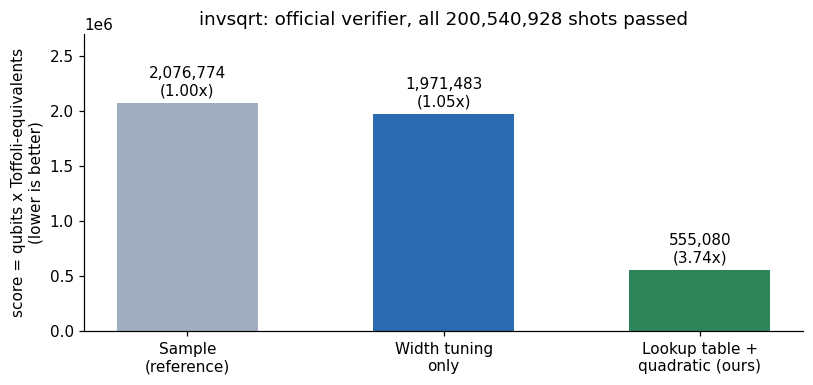

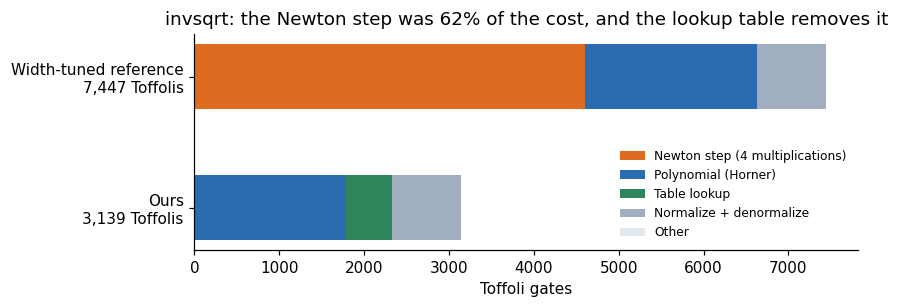

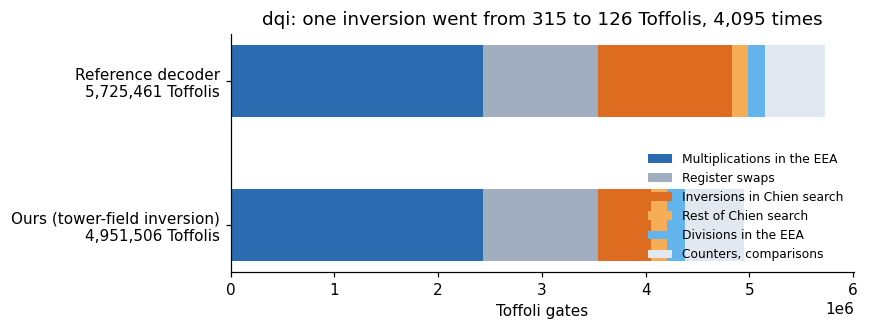

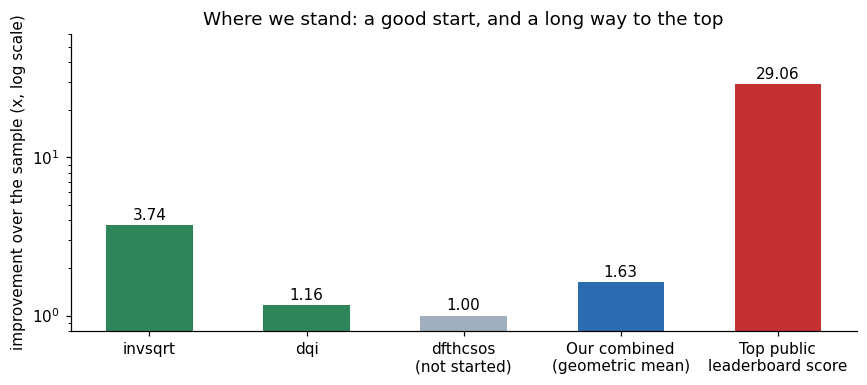

In [26]:
import matplotlib.pyplot as plt
 
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, GREY, RED = "#2b6cb0", "#dd6b20", "#2f855a", "#a0aec0", "#c53030"
 
fig, ax = plt.subplots(figsize=(7.5, 3.6))
labels = ["Sample\n(reference)", "Width tuning\nonly", "Lookup table +\nquadratic (ours)"]
scores = [2_076_774, 1_971_483, 555_080]
bars = ax.bar(labels, scores, color=[GREY, BLUE, GREEN], width=0.55)
for b, s in zip(bars, scores):
    ax.text(b.get_x() + b.get_width() / 2, s + 40_000, f"{s:,}\n({scores[0] / s:.2f}x)",
            ha="center", va="bottom")
ax.set_ylim(0, 2_700_000)
ax.set_ylabel("score = qubits x Toffoli-equivalents\n(lower is better)")
ax.set_title("invsqrt: official verifier, all 200,540,928 shots passed")
plt.tight_layout(); plt.show()
 
fig, ax = plt.subplots(figsize=(8, 2.9))
rows = ["Width-tuned reference\n7,447 Toffolis", "Ours\n3,139 Toffolis"]
parts = [("Newton step (4 multiplications)", [4606, 0], ORANGE),
         ("Polynomial (Horner)",             [2028, 1778], BLUE),
         ("Table lookup",                    [0, 551], GREEN),
         ("Normalize + denormalize",         [810, 810], GREY),
         ("Other",                           [3, 0], "#e2e8f0")]
left = [0, 0]
for name, vals, col in parts:
    ax.barh(rows, vals, left=left, color=col, label=name, height=0.5)
    left = [l + v for l, v in zip(left, vals)]
ax.invert_yaxis(); ax.set_xlabel("Toffoli gates"); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("invsqrt: the Newton step was 62% of the cost, and the lookup table removes it")
plt.tight_layout(); plt.show()
 
fig, ax = plt.subplots(figsize=(8, 3.1))
rows = ["Reference decoder\n5,725,461 Toffolis", "Ours (tower-field inversion)\n4,951,506 Toffolis"]
parts = [("Multiplications in the EEA",  [2_430_600, 2_430_600], BLUE),
         ("Register swaps",             [1_107_264, 1_107_264], GREY),
         ("Inversions in Chien search", [1_289_925, 515_970],  ORANGE),
         ("Rest of Chien search",       [154_812, 154_812],    "#f6ad55"),
         ("Divisions in the EEA",       [167_832, 167_832],    "#63b3ed"),
         ("Counters, comparisons",      [575_028, 575_028],    "#e2e8f0")]
left = [0, 0]
for name, vals, col in parts:
    ax.barh(rows, vals, left=left, color=col, label=name, height=0.5)
    left = [l + v for l, v in zip(left, vals)]
ax.invert_yaxis(); ax.set_xlabel("Toffoli gates")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("dqi: one inversion went from 315 to 126 Toffolis, 4,095 times")
plt.tight_layout(); plt.show()
 
fig, ax = plt.subplots(figsize=(8, 3.6))
names = ["invsqrt", "dqi", "dfthcsos\n(not started)", "Our combined\n(geometric mean)", "Top public\nleaderboard score"]
vals = [3.74, 1.16, 1.00, 1.63, 29.06]
cols = [GREEN, GREEN, GREY, BLUE, RED]
bars = ax.bar(names, vals, color=cols, width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v * 1.08, f"{v:.2f}", ha="center")
ax.set_yscale("log"); ax.set_ylim(0.8, 60)
ax.set_ylabel("improvement over the sample (x, log scale)")
ax.set_title("Where we stand: a good start, and a long way to the top")
plt.tight_layout(); plt.show()
 

In [27]:
base = "/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation"
src = open(base + "/verifiers/dfthcsos/SCORING_README.md").read()
print(src[:12000])

# `dfthcsos`: the DFTHC-SOS competition verifier

This package scores submissions to the Qaggle DFTHC-SOS competition. It is the
`verifier/` directory of the dfthc-sos repository, copied here and reduced to
the one system the competition is scored against:

| | |
| --- | --- |
| System | **FeMoCo76o113e**: `N = 76` spatial orbitals, `eta = 113` electrons |
| `E_upper` | `-22140.27335` Ha |
| Provided baseline | `R, B, C = 65, 60, 60` |
| Fixed symmetry shift | `S, beta_1` of the provided baseline, from [FeMoCo76o113e.fixed_shifts.npz](FeMoCo76o113e.fixed_shifts.npz) (SHA-256 `7b7facf63fe35a9d9d3d00787ffdb700c863fa845fe4724d7f7c54778151cd87`); submitted `H1_I` and `Hsym_lower` are ignored |
| Strict acceptance thresholds | Raw LCU normalization `Lambda > 49.0` and `E_gap > 3.914898` Ha; equality is rejected |
| Reference integrals | [FeMoCo76o113e.fcidump](FeMoCo76o113e.fcidump), shipped in this directory (128,128,348 bytes, SHA-256 `e5a48af746fd075026dec9e8f5df2d363802a121e8c53af9a0b98